# Day 04 - 神经网络基础2

## 学习目标
- 动手实现搭建神经网络
- 掌握常用损失函数
- 掌握梯度下降算法
- 了解反向传播算法
- 掌握梯度下降的优化方法

In [1]:
# 导包
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']  # 微软雅黑
plt.rcParams['axes.unicode_minus'] = False            # 解决负号显示问题
# 设置设备
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"当前设备：{DEVICE}")

当前设备：cuda


## day04_01.搭建神经网络

<img src="./assets/image-20220313141138281.png" alt="演示搭建神经网络" style="zoom:50%;" />

In [2]:
"""
演示
    搭建神经网络，这里是一个简单的全连接神经网络
这里的全连接神经网络组成：
    隐藏层1：nn.Linear(3,3),权重初始化采用标准化的xavier初始化 激活函数使用sigmoid
    隐藏层2：nn.Linear(3,2),权重初始化采用标准化的He初始化 激活函数采用relu
    输出层: nn.Linear(2,2),采用softmax做数据归一化，权重初始化采用标准化的xavier初始化

深度学习/神经网络训练的一般工作流
    1.准备数据集
    2.搭建神经网络
        继承nn.Module父类
        定义__init__方法，定义网络层
        定义forward方法，实现前向传播
    3.模型训练
        前向传播
        计算损失
        梯度清零
        反向传播
        更新参数
    4.模型测试

"""
# 导包
import torch
from torch import nn
from torchsummary import summary  # 计算模型参数,查看模型结构, pip install torchsummary -i https://mirrors.aliyun.com/pypi/simple/

# 设置设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"设备:{device}")

# 1.定义模型类，搭建神经网络
class MyModel(nn.Module):
    # 1.定义__init__方法，定义网络层,并且进行参数初始化
    def __init__(self):
        # 1.初始化父类成员
        super().__init__()
        # 2.定义网络层
        # 2.1 定义隐藏层1
        self.linear1 = nn.Linear(3,3)
        # 2.2 定义隐藏层2
        self.linear2 = nn.Linear(3,2)
        # 2.3 定义输出层
        self.linear3 = nn.Linear(2,2)
        # 3.参数初始化
        # 3.1 隐藏层1的参数初始化
        nn.init.xavier_normal_(self.linear1.weight)
        nn.init.zeros_(self.linear1.bias)
        # 3.2 隐藏层2的参数初始化
        nn.init.kaiming_normal_(self.linear2.weight)
        nn.init.zeros_(self.linear2.bias)
        # 3.3 输出层的参数初始化
        nn.init.xavier_normal_(self.linear3.weight)
        nn.init.zeros_(self.linear3.bias)
        ...
    # 2.定义forward方法，实现前向传播
    def forward(self,x):
        # 1.把数据输入隐藏层1
        # x = self.linear1(x)
        # # 经过sigmoid
        # x = torch.sigmoid(x)
        # 合起来写
        x = torch.sigmoid(self.linear1(x))
        # 2.把数据输入隐藏层2
        x = torch.relu(self.linear2(x))
        # 3.把数据输入输出层
        x = torch.softmax(self.linear3(x),dim=-1)
        # 4.返回结果
        return x


# 2.模型训练
def train():
    # 1.创建模型对象
    model = MyModel()
    print(model)
    model = model.to(device)
    # 2.查看模型的参数数量
    summary(model,(3,))
    ...

# 测试
if __name__ == '__main__':
    # model = MyModel()
    # 查看模型参数数量
    train()
    ...

设备:cuda
MyModel(
  (linear1): Linear(in_features=3, out_features=3, bias=True)
  (linear2): Linear(in_features=3, out_features=2, bias=True)
  (linear3): Linear(in_features=2, out_features=2, bias=True)
)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                    [-1, 3]              12
            Linear-2                    [-1, 2]               8
            Linear-3                    [-1, 2]               6
Total params: 26
Trainable params: 26
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


## 4. 损失函数

###  损失函数概念

在深度学习中, 损失函数是用来**衡量模型参数质量的函数**, 衡量的方式**是比较网络输出（预测值）和真实输出（真实值）的差异。**

我们通过最小化损失函数的值来调整模型参数，使其输出更接近真实值。

<!-- ![image-20200730153842351](assets/03-1.png) -->
<img src="assets/03-1.png" alt="image-20200730153842351" style="zoom:80%;" />

损失函数在不同的文献中名称是不一样的，主要有以下几种**命名方式**：

<img src="assets/03-2.png" alt="image-20200730154850183" style="zoom:50%;" />

**损失函数作用：**

- **评估性能**：反映模型预测结果与目标值的匹配程度。
- **指导优化**：通过梯度下降等算法最小化损失函数，优化模型参数。

### 多分类交叉熵损失 - nn.CrossEntropyLoss()
**分类任务**中使用最多的是**交叉熵损失函数**, 多分类交叉熵损失函数中包含了softmax运算，模型输出层无需softmax

在多分类任务通常使用softmax将logits转换为概率的形式，所以多分类交叉熵损失也叫做**softmax损失**，计算方法是：
$$ loss = - \sum_{i=1}^q y_i \log(softmax(\hat{y}_i)) $$

其中:

- $y_i$ 是样本x属于某一个类别的真实概率
- 而 $\hat{y}_i$ 是样本属于某一类别的预测分数logits
- $softmax(\hat{y}_i)$是预测概率
- $loss$用来衡量真实值$y_i$和预测值$\hat{y}_i$之间的差距

例子：

<img src="assets/03-4.png" alt="image-20200730160805389" style="zoom: 67%;" />

上图中的交叉熵损失为：
$$-(0log(0.10) + 1log(0.70) + 0log(0.2)) = -log(0.7)$$

从概率角度理解，我们的目的是最小化正确类别所对应的预测概率的对数的负值(损失值最小)，如下图所示：

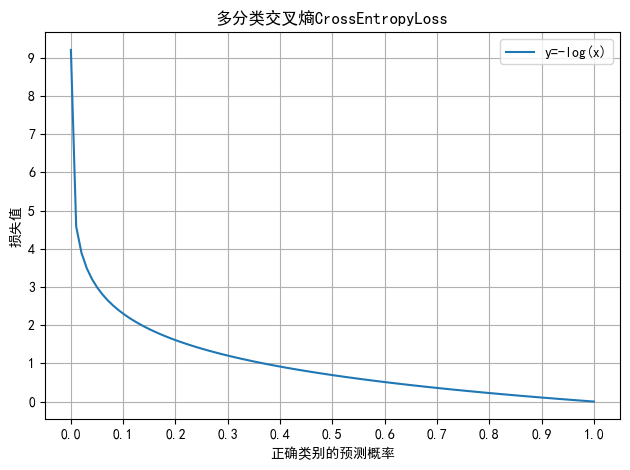

In [3]:
# 绘制 y=-log(x) 曲线
x = np.linspace(1e-4, 1, 100) 
y = -np.log(x)
# 设置x刻度为0到1
plt.xticks(np.arange(0, 1.1, 0.1))
plt.yticks(np.arange(0, 10, 1))
# 设置坐标轴标签
plt.xlabel("正确类别的预测概率")
plt.ylabel("损失值")
plt.plot(x, y, label="y=-log(x)")
plt.grid(True)
plt.title("多分类交叉熵CrossEntropyLoss")
plt.tight_layout()
plt.legend()
plt.show()

In [4]:
"""
案例：
    演示 多分类交叉熵损失函数

介绍：
    损失函数 也叫 成本函数，目标函数，代价函数，误差函数，用来 衡量模型好坏，也就是模型预测表现
    分类问题：
        多分类交叉熵损失CrossEntropyLoss

多分类交叉熵损失CrossEntropyLoss
    公式：CrossEntropyLoss = -Σylog(S(f(x)))
    其中，x: 样本，f(x): 模型预测的原始输出logits，S(f(x)): 模型预测的概率分布，y:样本x属于某个类别的 真实概率，比如[0,0,1]
    注意：
        CrossEntropyLoss内部进行了Softmax运算，模型输出层无需进行softmax运算，除非在新的数据上预测类别，需要获取预测概率，则需要在模型的原始输出logits上进行softmax

"""

# 导包
import torch
# 1.定义函数，演示 多分类交叉熵损失函数
def demo01():
    # 1.创建 样本的真实类别,针对一个三分类任务，3个样本，真实类别为0，0，1
    # 1.1 使用 one-hot 编码
    # y_true = torch.tensor([[1,0,0],[1,0,0],[0,1,0]], dtype=torch.float)
    # 1.2 使用label编码
    y_true = torch.tensor([0,0,1])
    # 2.创建 模型预测的原始输出logits
    y_logits = torch.tensor([[1.5,0.2,0.9],[0.1,2,0.9],[0.1,0.2,9.4]], requires_grad=True)
    # 3.创建多分类交叉熵损失函数对象
    loss_fn = torch.nn.CrossEntropyLoss()
    # 4.计算损失值
    loss = loss_fn(y_logits,y_true)
    print(f"损失值：{loss}")
    
# 测试
if __name__ == '__main__':
    demo01()

损失值：4.03115177154541


### 二分类交叉熵损失 - nn.BCELoss()
**二分类任务**中可以使用**二分类交叉熵损失函数** 和 **sigmoid**

公式为：
$$loss = -y \log(\hat{y}) - (1-y)\log(1-\hat{y})$$

其中:

- y 是样本x属于某一个类别的真实概率

- 而 $\hat{y}$ 是样本属于某一类别的预测概率

- loss用来衡量真实值 y 与预测值 $\hat{y}$ 之间差异的损失函数

C:\Users\angmi\AppData\Local\Temp\ipykernel_38288\193180856.py:4: RuntimeWarning: divide by zero encountered in log
  y2 = -np.log(1 - x)


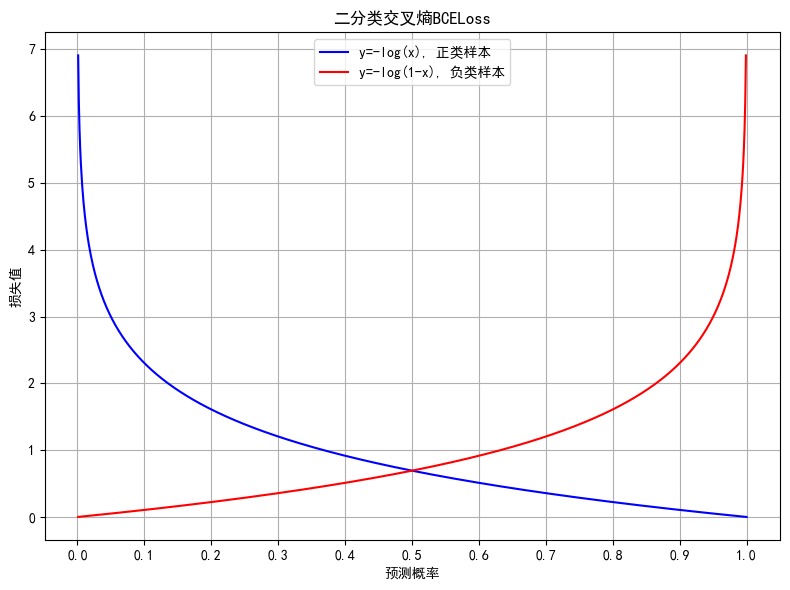

In [5]:
# 绘制 y = -log(x), y=-log(1-x)
x = np.linspace(1e-3, 1, 1000)  # 避免对数函数的零值
y1 = -np.log(x)
y2 = -np.log(1 - x)
plt.figure(figsize=(8, 6))
plt.xticks(np.arange(0, 1.1, 0.1))
plt.yticks(np.arange(0, 10, 1))
plt.xlabel("预测概率")
plt.ylabel("损失值")
plt.plot(x, y1, color='blue', label='y=-log(x), 正类样本')
plt.plot(x, y2, color='red', label='y=-log(1-x), 负类样本')
plt.grid(True)
plt.title("二分类交叉熵BCELoss")
plt.legend()
plt.tight_layout()
plt.show()

针对二分类问题，CrossEntropyLoss(softmax) 和 BCELoss(sigmoid) 可以互相转化

In [6]:
"""
案例：
    演示 二分类交叉熵损失函数
介绍：
    损失函数 也叫 成本函数，目标函数，代价函数，误差函数，用来 衡量模型好坏，模型预测表现
    分类问题：
        多分类交叉熵损失CrossEntropyLoss
        二分类交叉熵损失BCELoss
多分类交叉熵损失CrossEntropyLoss
    公式：CrossEntropyLoss = -Σylog(S(f(x)))
    其中，x: 样本，f(x): 模型预测的原始输出logits，S(f(x)): 模型预测的概率分布，y:样本x属于某个类别的 真实概率，比如[0,0,1]
    注意：
        CrossEntropyLoss内部进行了Softmax运算，模型输出层无需进行softmax运算，除非在新的数据上预测类别，需要获取预测概率，则需要在模型的原始输出logits上进行softmax

二分类交叉熵损失BCELoss
    公式：BCELoss = -ylog(y_hat)-(1-y)log(1-y_hat)
    注意：
        BCELoss内部没有进行sigmoid运算，使用BCELoss时，模型输出层需要手动添加sigmoid

针对二分类问题，CrossEntropyLoss 和 BCELoss 可以互相转化
注意正类的人为设定，会影响BCELoss 和 CrossEntropyLoss 中 logits的 转换关系
"""


# 导包
import torch
import torch.nn as nn

# 定义函数，演示 二分类交叉熵损失
def demo01():
    print("二分类交叉熵损失")
    # 1. 创建 样本的真实类别, [正，正，负]
    y_true = torch.tensor([1, 1, 0], dtype=torch.float)

    # 2.创建 模型预测 的原始输出logits值
    y_logits = torch.tensor([1,-4,3], dtype=torch.float)
    # sigmoid=1/(1+exp(-x))
    # 经过sigmoid,转化为正类别的 概率
    y_pred = torch.sigmoid(y_logits)
    print(f"y_pred: {y_pred}")

    # 3.创建 交叉熵损失函数
    loss_fn = nn.BCELoss()

    # 4.计算损失
    loss = loss_fn(y_pred, y_true)
    print(f"loss: {loss}")
    
# 定义函数，演示 多分类交叉熵损失
def demo02():
    print("多分类交叉熵损失")
    # 1. 创建 样本的真实类别, [正，正，负]
    y_true = torch.tensor([1, 1, 0])

    # 2.创建 模型预测 的原始输出logits值
    y_pred = torch.tensor([[2,3], [5,1],[1, 4]], dtype=torch.float)

    # 3.创建 交叉熵损失函数
    loss_fn = nn.CrossEntropyLoss()

    # 4.计算损失
    loss = loss_fn(y_pred, y_true)
    print(f"loss: {loss}")
    
# 测试
if __name__ == '__main__':
    demo01()
    demo02()

二分类交叉熵损失
y_pred: tensor([0.7311, 0.0180, 0.9526])
loss: 2.4599997997283936
多分类交叉熵损失
loss: 2.4599995613098145


### 回归任务 - MAE损失函数

**mean absolute loss(MAE)** 也被称为L1 Loss，计算绝对误差的平均值

损失函数公式:
$$L = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|$$

误差-损失曲线如下图所示：

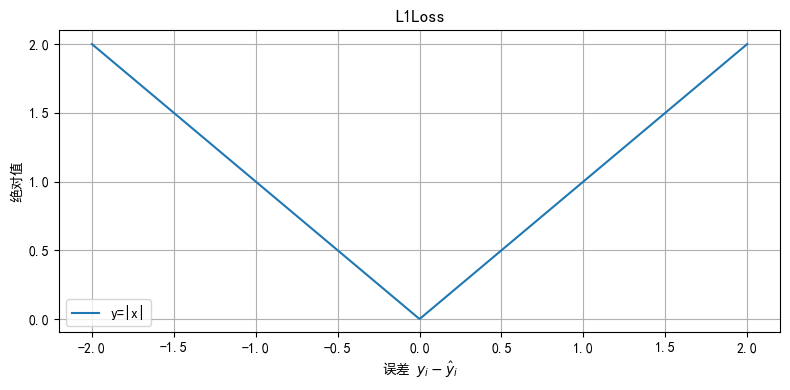

In [7]:
# 绘制 y=|x|的函数图像
x = np.linspace(-2, 2, 1000)
y = np.abs(x)
plt.figure(figsize=(8, 4))
plt.plot(x, y, label="y=|x|")
# 设置坐标轴标签
plt.xlabel(r"误差 $y_i - \hat{y}_i$")
plt.ylabel("绝对值")
# 设置刻度
plt.xticks(np.arange(-2, 2.5, 0.5))
plt.yticks(np.arange(0, 2.5, 0.5))
plt.title("L1Loss")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

特点是：

- 损失-误差呈线性关系
- MAE损失函数本身不具有稀疏性，不会让权重衰减为0。
- 最大问题是梯度在零点不平滑，会跳过极小值。
- 适用于回归问题中存在异常值或噪声数据时，可以减少对离群点的敏感性

In [8]:
# 定义变量，记录 真实值
y_true = torch.tensor([2.0,2.5,3.0], dtype=torch.float)
# 定义变量，记录 预测值
y_pred = torch.tensor([1.5,2.0,2.5], dtype=torch.float, requires_grad=True)
# 创建损失函数，MAE
loss_fn = nn.L1Loss()
# loss_fn = nn.MSELoss()
# loss_fn = nn.SmoothL1Loss()
# 计算损失值
loss = loss_fn(y_pred, y_true)
# 打印损失值
print(f"MAE: {loss}")

MAE: 0.5


### 回归任务 - MSE损失函数

**Mean Squared Loss/ Quadratic Loss(MSE loss)** 也被称为L2 loss，或欧氏距离，计算误差平方的平均值

公式:
$$L = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

误差-损失曲线如下图所示：

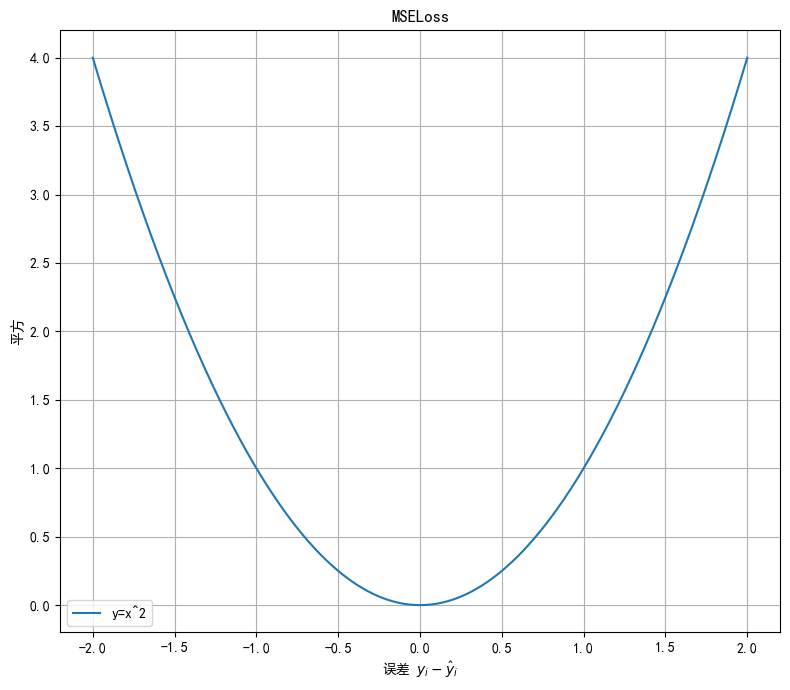

In [9]:
# 绘制 y=x^2 的函数图像
x = np.linspace(-2, 2, 1000)
y = x ** 2
plt.figure(figsize=(8, 7))
plt.plot(x, y, label="y=x^2")
# 设置坐标轴标签
plt.xlabel(r"误差 $y_i - \hat{y}_i$")
plt.ylabel("平方")
# 设置刻度
plt.xticks(np.arange(-2, 2.5, 0.5))
plt.yticks(np.arange(0, 4.5, 0.5))
plt.title("MSELoss")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

特点是：

- 损失-误差呈二次曲线关系
- 处处可导、梯度平滑，是最常用的回归损失函数
- 误差大时, 容易梯度过大
- 适用于大多数标准回归问题，如房价预测、温度预测等

In [10]:
# 定义变量，记录 真实值
y_true = torch.tensor([2.0,2.5,3.0], dtype=torch.float)
# 定义变量，记录 预测值
y_pred = torch.tensor([1.5,2.0,2.5], dtype=torch.float, requires_grad=True)
# 创建损失函数，MSE
# loss_fn = nn.L1Loss()
loss_fn = nn.MSELoss()
# loss_fn = nn.SmoothL1Loss()
# 计算损失值
loss = loss_fn(y_pred, y_true)
# 打印损失值
print(f"MSE: {loss}")

MSE: 0.25


### 回归任务 - Smooth L1 Loss (也称为 Huber Loss)

Smooth L1 损失函数结合了 **MAE** 和 **MSE**，适用于回归任务，尤其是在面对异常值时，它能平滑过渡，避免大误差的影响。

公式如下：

$$
L_{\text{SmoothL1}} = \frac{1}{n} \sum_{i=1}^{n} 
\begin{cases} 
0.5 \cdot (x_i)^2 & \text{if } |x_i| < 1 \\
|x_i| - 0.5 & \text{if } |x_i| \geq 1
\end{cases}
$$

其中：
- $x_i = y_{\text{pred}, i} - y_{\text{true}, i}$
- $n$ 是样本数量
- $x_i$ 是每个样本的预测误差

**解释：**
- 当误差 $|x_i|$ 小于 1 时，使用 **L2 损失**（平方误差），这意味着损失的增长是 **二次方**，避免了在训练过程中使用绝对误差导致的梯度不连续问题。
- 当误差 $|x_i|$ 大于或等于 1 时，使用 **L1 损失**（绝对误差），避免了大误差对梯度的影响，避免了MSE对离群点过度敏感，可以减少梯度爆炸。

这种方式使得 **Smooth L1 Loss** 在小误差时更精确，在大误差时能较为稳健地优化。

Smooth L1损失函数图像为：

<img src="assets/03-13.png"  style="zoom:50%;" />

从上图中可以看出，该函数实际上就是一个分段函数

- 在[-1,1]之间实际上就是L2损失，这样解决了L1的不光滑问题
- 在[-1,1]区间外，实际上就是L1损失，这样就解决了离群点梯度爆炸的问题

In [11]:
# 定义变量，记录 真实值
y_true = torch.tensor([2.0,2.5,3.0], dtype=torch.float)
# 定义变量，记录 预测值
y_pred = torch.tensor([1.5,2.0,2.5], dtype=torch.float, requires_grad=True)
# 创建损失函数，SmoothL1Loss
# loss_fn = nn.L1Loss()
# loss_fn = nn.MSELoss()
loss_fn = nn.SmoothL1Loss()
# 计算损失值
loss = loss_fn(y_pred, y_true)
# 打印损失值
print(f"SmoothL1Loss: {loss}")

SmoothL1Loss: 0.125


## 5.神经网络优化方法

多层神经网络的学习能力优于单层网络。想要训练多层网络，需要通用的学习算法，一般是反向传播算法（Back Propagation）和梯度下降法。BP 算法不仅可用于全连接神经网络，还可以用于其他类型的网络。BP 网络，一般是指用 BP 算法训练的全连接神经网络。

两个概念：

1. **前向传播**：数据通过网络从输入层到输出层的传递过程。计算网络的输出值（预测值），从而与目标值（真实值）比较以计算误差。
2. **反向传播**：计算损失函数相对于网络中各参数（权重和偏置）的梯度，指导优化器更新参数，从而降低损失值。

## 6. 梯度下降法

**梯度下降法**就是一种**寻找损失函数最小值的方法**。从数学角度来看，**梯度的方向是函数增长速度最快的方向，梯度的反方向就是函数减少最快的方向**。

### 基本步骤
1. 初始化参数
2. 前向传播计算损失
3. 反向传播计算梯度
4. 更新参数: 
$$w = w - \alpha * \frac{\partial L}{\partial w}$$
其中$\alpha$是学习率。如果学习率**太小**，那么每次训练之后得到的参数更新效果都太小，**增大训练的时间成本**。如果，学习率**太大**，那就有可能**直接跳过最优解**，进入无限的训练中。解决的方法是，学习率也需要随着训练的进行而变化。

$\frac{\partial L}{\partial w}$ 是损失函数对模型参数的梯度。

<img src='assets/04-05.png' />

在上图中我们展示了一维和多维的损失函数，损失函数呈碗状。在训练过程中损失函数对权重的偏导数就是损失函数在该位置的梯度。可以看到，沿着负梯度方向移动，就可以到达损失函数底部，从而使损失函数最小化。这种利用损失函数的梯度迭代地寻找最小值的过程就是梯度下降的过程。

$$
\frac{\partial \text{loss}}{\partial (w_1, w_2)} = (2w_1, 2w_2)
$$

**在进行模型训练时，有三个基础的概念：**

1. **Epoch**: 训练轮数，使用全部数据对模型进行此轮完整训练，比如 `Epochs = 100`
2. **Batch**: 批次大小，使用训练集中的小部分样本的梯度对模型权重进行更新,比如 `batch_size=16`
3. **Iteration**: 每次训练的批次数，使用一个 Batch 数据对模型进行一次参数更新的过程，比如 `iterations=7`

假设数据集有 50000 个训练样本，现在选择 Batch Size = 256 对模型进行训练。
- 每个 Epoch 要训练的图片数量：50000 
- 训练集具有的 Batch 个数：(50000-1)//256+1=196
- 每个 Epoch 具有的 Iteration 个数：196 
- 10个 Epoch 具有的 Iteration 个数：1960

在深度学习中，**梯度下降的几种方式的根本区别就在于Batch Size不同**,如下表所示：
| 梯度下降方式 | Training Set Size | Batch Size | Number of Batches |
|--------------|-------------------|------------|-------------------|
| BGD          | $N$               | $N$        | $1$               |
| SGD          | $N$               | $1$        | $N$               |
| Mini-Batch   | $N$               | $B$        | $ (N-1)//B + 1 $ |

演示梯度下降法

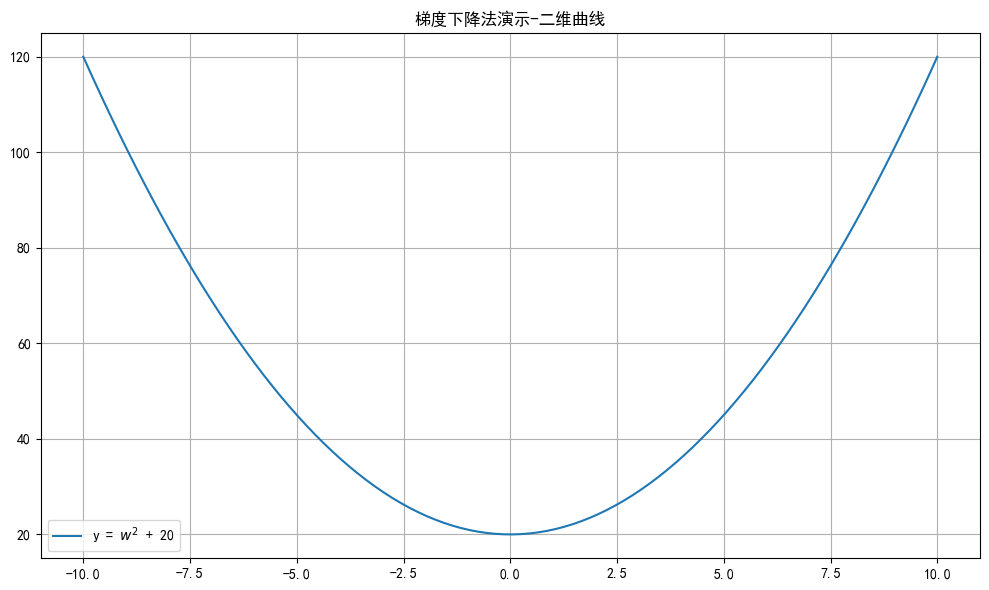

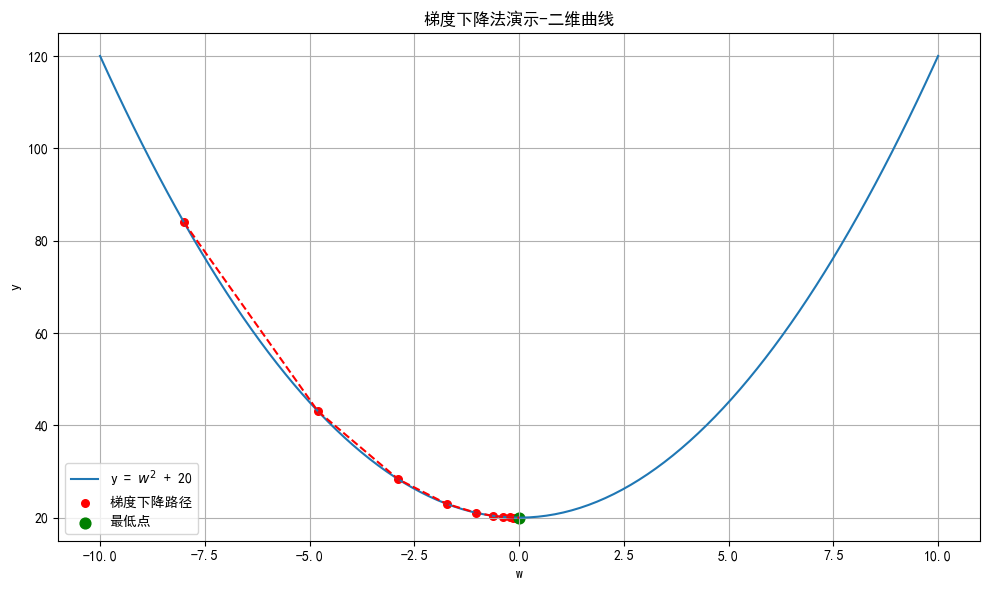

In [12]:
# 目标函数 & 导数
def f(x):
    return x**2 + 20

def grad(x):
    return 2 * x

# 准备绘图
x_vals = np.linspace(-10, 10, 200)
y_vals = f(x_vals)

plt.figure(figsize=(10,6))
plt.title("梯度下降法演示-二维曲线")
plt.plot(x_vals,y_vals, label="y = $w^{2}$ + 20")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

# 梯度下降参数
lr = 0.2          # learning rate
x = -8            # 初始点
steps = 20        # 迭代次数

xs = [x]          # 保存每一步的 x
ys = [f(x)]       # 保存每一步的 y

# 梯度下降过程
for i in range(steps):
    g = grad(x)
    x = x - lr * g
    xs.append(x)
    ys.append(f(x))

# 绘制函数曲线
plt.figure(figsize=(10,6))
plt.plot(x_vals, y_vals, label=r"y = $w^{2}$ + 20")

# 绘制梯度下降路径
plt.scatter(xs, ys, color='red', s=30, label="梯度下降路径")
plt.plot(xs, ys, color='red', linestyle='--')

# 最终点标注
plt.scatter(xs[-1], ys[-1], color='green', s=60, label="最低点")

plt.grid()
plt.legend()
plt.title("梯度下降法演示-二维曲线")
plt.xlabel("w")
plt.ylabel("y")
plt.tight_layout()
plt.show()

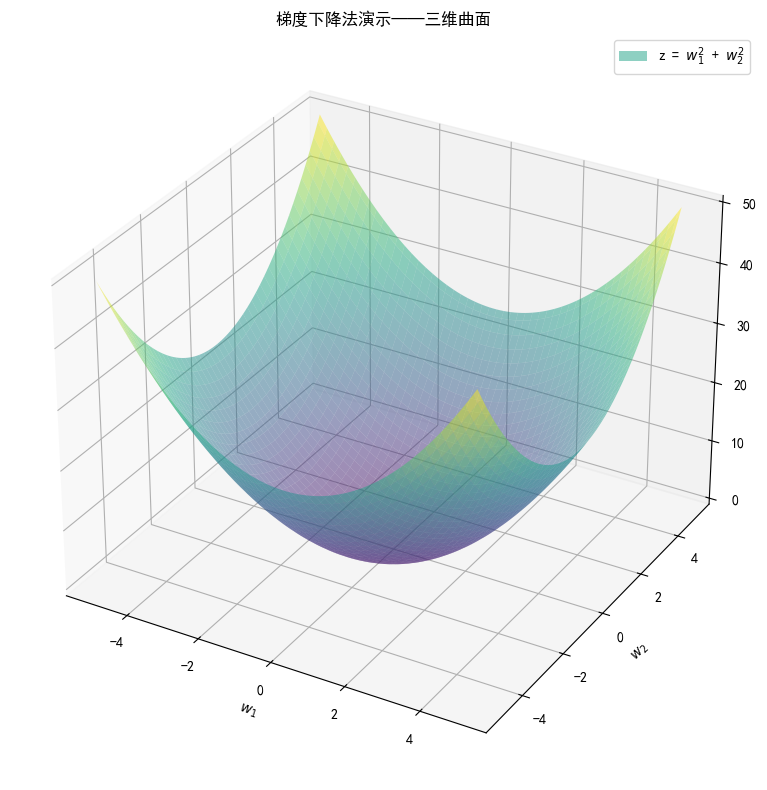

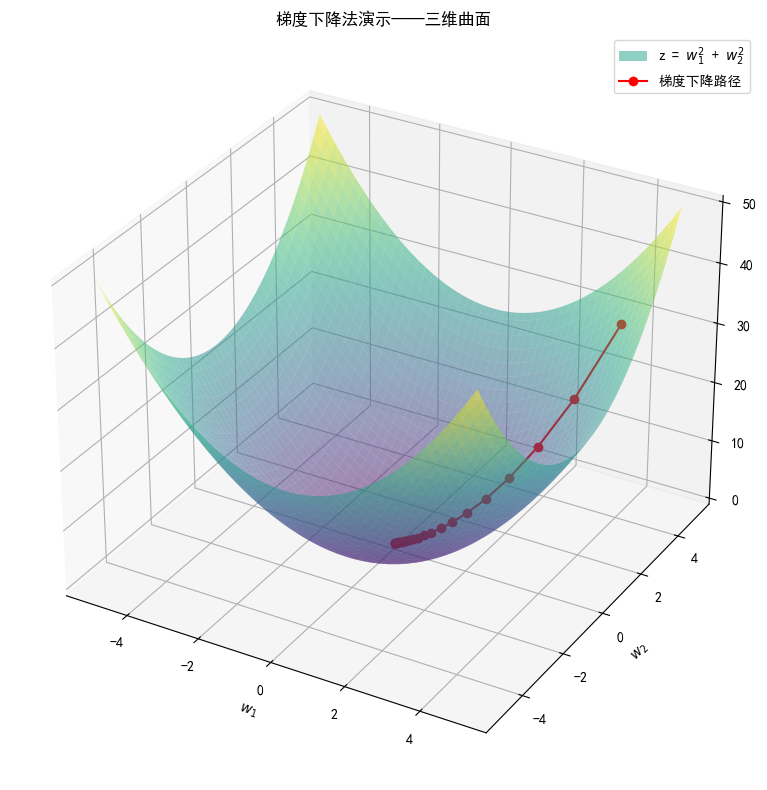

In [13]:
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

# 定义函数及梯度
def f(x, y):
    return x**2 + y**2

def grad_f(x, y):
    return np.array([2*x, 2*y])

# 创建网格
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x, y)
Z = f(X, Y)

# 梯度下降初始化
lr = 0.1  # 学习率
steps = 25
point = np.array([4.0, 4.0])  # 起点
trajectory = [point.copy()]

# 梯度下降迭代
for _ in range(steps):
    grad = grad_f(point[0], point[1])
    point -= lr * grad
    trajectory.append(point.copy())

trajectory = np.array(trajectory)
Z_traj = f(trajectory[:,0], trajectory[:,1])

# 绘图
# Plot surface
fig = plt.figure(figsize=(12,8))
ax = fig.add_subplot(111, projection='3d')
ax.set_title("梯度下降法演示——三维曲面")
ax.plot_surface(X, Y, Z, alpha=0.5, cmap='viridis', label="z = $w_1^{2}$ + $w_2^{2}$")  # No colors specified
ax.set_xlabel(r"$w_1$")
ax.set_ylabel(r"$w_2$")
ax.legend()
plt.tight_layout()

fig = plt.figure(figsize=(12,8))
ax = fig.add_subplot(111, projection='3d')
ax.set_title("梯度下降法演示——三维曲面")
ax.plot_surface(X, Y, Z, alpha=0.5, cmap='viridis', label="z = $w_1^{2}$ + $w_2^{2}$")  # 半透明曲面
ax.plot(trajectory[:,0], trajectory[:,1], Z_traj, color='r', marker='o', label='梯度下降路径')

ax.set_xlabel(r"$w_1$")
ax.set_ylabel(r"$w_2$")
# ax.set_zlabel(r"z = $w_1^{2}$ + $w_2^{2}$")
ax.legend()
plt.tight_layout()
plt.show()

## 7.反向传播（BP算法）

> 利用**反向传播算法**对神经网络进行训练。该方法与**梯度下降算法**相结合，对网络中所有权重**计算损失函数的梯度**，并利用梯度值来**更新权值**以最小化损失函数。

### 概念

**前向传播**：数据输入到神经网络中，逐层向前传播，一直运算到输出层为止, 输出预测值。

**反向传播（Back Propagation）**：利用损失函数loss值，从后往前，依次求各个参数的偏导，结合梯度下降算法，更新模型参数。

<img src='assets/141.png' />

在网络的训练过程中经过前向传播得到的最终结果跟训练样本的真实值总是存在一定误差，这个误差便是损失函数 ERROR。想要减小这个误差，**就用损失函数 ERROR，从后往前，依次求各个参数的偏导，这就是反向传播（Back Propagation）, 然后用损失梯度来更新模型参数来减小损失值**。

### 详解

**反向传播算法利用链式求导法则对神经网络中的各个节点的权重进行求导运算**。

【举个栗子🌰：】

下图是一个简单的神经网络示例：**激活函数为sigmoid**

<img src="assets/image-20210129103846076.png" alt="image-20210129103846076" style="zoom:50%;" />

**前向传播运算**：

<img src="assets/image-20210129104612230.png" alt="image-20210129104612230" style="zoom:70%;" />

**反向传播运算**（求损失函数对各个模型参数的梯度）：

先来求损失函数E对$w_{5}$的导数。根据**链式求导法则**，损失函数E对$w_{5}$的导数为：

$$\frac{\partial E}{\partial w_{5}} = \frac{\partial E}{\partial out_{o1}} * \frac{\partial out_{o1}}{\partial net_{o1}} * \frac{\partial net_{o1}}{\partial w_{5}}$$

如下图所示：

<img src="assets/image-20210129104646474.png" alt="image-20210129104646474" style="zoom:70%;" />

导数（梯度）已经计算出来了，下面就是**更新参数过程**：

<img src="assets/image-20210129104718140.png" alt="image-20210129104718140" style="zoom:70%;" />

**损失函数E对$w_{1}$的导数**，损失函数E对$w_{1}$的求导路径不止一条，这会稍微复杂一点，但换汤不换药，计算过程如下所示：

<img src="assets/image-20210129104756053.png" alt="image-20210129104756053" style="zoom:70%;" />

## 8.梯度下降优化方法

梯度下降优化算法中，可能会碰到以下情况：

- 碰到平缓区域，梯度值较小，参数优化变慢
- 碰到 “鞍点” ，梯度为0，参数无法优化
- 碰到局部最小值，参数不是最优

对于这些问题, 出现了一些对梯度下降算法的优化方法，例如：**Momentum**、**AdaGrad**、**RMSprop**、**Adam** 等

<img src='assets/50.png' style="zoom:50%;" />

###  指数加权平均

常见的算数平均指的是将所有数加起来除以数的个数，每个数的权重是相同的。指数加权平均指的是给每个数赋予不同的权重求平均数。移动平均数，指的是计算最近邻的 N 个数来获得平均数。

**指数移动加权平均**则是参考各数值，并且各数值的权重都不同，距离越远的数字对平均数计算的贡献越小（权重较小），距离越近则对平均数计算的贡献越大（权重越大）。

比如：明天气温怎么样，和昨天气温有很大关系，而和一个月前的气温关系就小一些。

计算公式可以用下面的式子来表示：

$$
S_t = \begin{cases} 
Y_0, & t = 0 \\ 
\beta * S_{t-1} + (1 - \beta) * Y_t, & t > 0 
\end{cases}
$$

- $S_t$ 表示指数加权平均值;
- $Y_t$ 表示t时刻的值;
- β 调节权重系数，该值越大平均数越平缓。

举个例子，假设 权重 $\beta$ 为 0.9，则：

- $S_0 = Y_0 $
- $S_1 = 0.9 \times S_0 + 0.1 \times Y_1$
- $S_2 = 0.9 \times S_1 + 0.1 \times Y_2 = 0.9^2 \times Y_0 + 0.9 \times 0.1 \times Y_1 + 0.1 \times Y_2$
- $S_3 = 0.9 \times S_2 + 0.1 \times Y_3 = 0.9^3 \times Y_0 + 0.9^2 \times 0.1 \times Y_1 + 0.9 \times 0.1 \times Y_2 + 0.1 \times Y_3$
- ...
- $S_n = 0.9 \times S_{n-1} + 0.1 \times Y_n = 0.9^{n} \times Y_0 + 0.9^{n-1} \times 0.1 \times Y_1 + \dots + 0.9 \times 0.1 \times Y_{n-1} + 0.1 \times Y_n$

- $S_{100} = 0.9 \times S_{99} + 0.1 \times Y_{100} = 0.9^{100} \times Y_0 + 0.9^{99} \times 0.1 \times Y_1 + \dots + 0.9 \times 0.1 \times Y_{99} + 0.1 \times Y_{100} $

$$ = 0.1 \times Y_{100} + 0.9 \times 0.1 \times Y_{99} + 0.9^2 \times 0.1 \times Y_{98} + ...  $$

**结论**
1. $S_n$是 $[Y_0, Y_1, Y_2, ..., Y_n]$ 的加权求和结果 — 指数加权平均值
2. 离当前值$S_n$越近的数据，系数越大

tensor([-11.2584, -11.5236,  -2.5058,  -4.3388,   8.4871,   6.9201,  -3.1601,
        -21.1522,   3.2227, -12.6333,   3.4998,   3.0813,   1.1984,  12.3766,
         -1.4347,  -1.1161,  -6.1358,   0.3159,  -4.9268,   2.4841,   4.3970,
          1.1241,  -8.4106, -23.1604,  -1.0231,   7.9244,  -2.8967,   0.5251,
          5.2286,  23.0221])


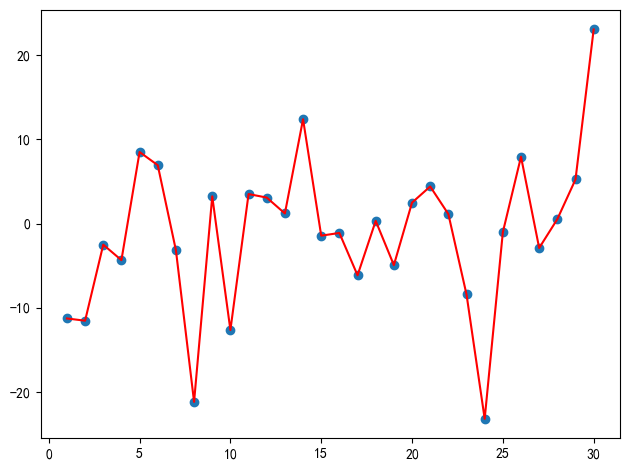

tensor([-11.2584, -11.5236,  -2.5058,  -4.3388,   8.4871,   6.9201,  -3.1601,
        -21.1522,   3.2227, -12.6333,   3.4998,   3.0813,   1.1984,  12.3766,
         -1.4347,  -1.1161,  -6.1358,   0.3159,  -4.9268,   2.4841,   4.3970,
          1.1241,  -8.4106, -23.1604,  -1.0231,   7.9244,  -2.8967,   0.5251,
          5.2286,  23.0221])


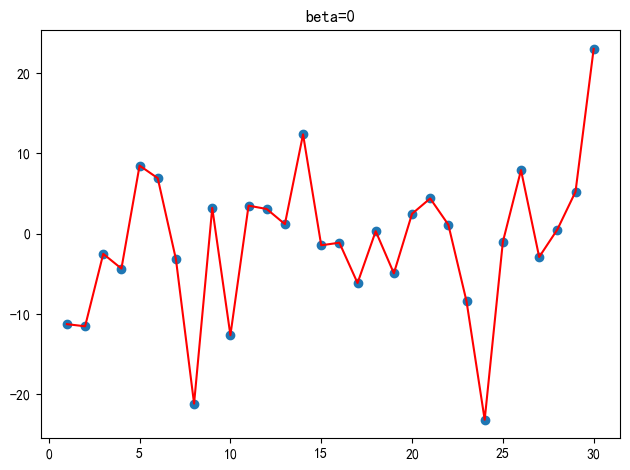

tensor([-11.2584, -11.5236,  -2.5058,  -4.3388,   8.4871,   6.9201,  -3.1601,
        -21.1522,   3.2227, -12.6333,   3.4998,   3.0813,   1.1984,  12.3766,
         -1.4347,  -1.1161,  -6.1358,   0.3159,  -4.9268,   2.4841,   4.3970,
          1.1241,  -8.4106, -23.1604,  -1.0231,   7.9244,  -2.8967,   0.5251,
          5.2286,  23.0221])


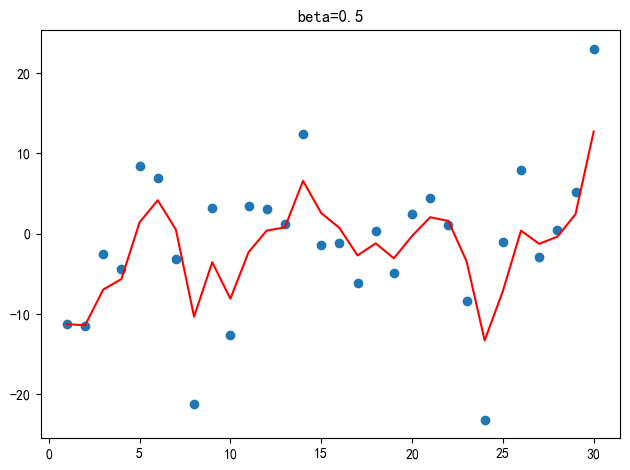

tensor([-11.2584, -11.5236,  -2.5058,  -4.3388,   8.4871,   6.9201,  -3.1601,
        -21.1522,   3.2227, -12.6333,   3.4998,   3.0813,   1.1984,  12.3766,
         -1.4347,  -1.1161,  -6.1358,   0.3159,  -4.9268,   2.4841,   4.3970,
          1.1241,  -8.4106, -23.1604,  -1.0231,   7.9244,  -2.8967,   0.5251,
          5.2286,  23.0221])


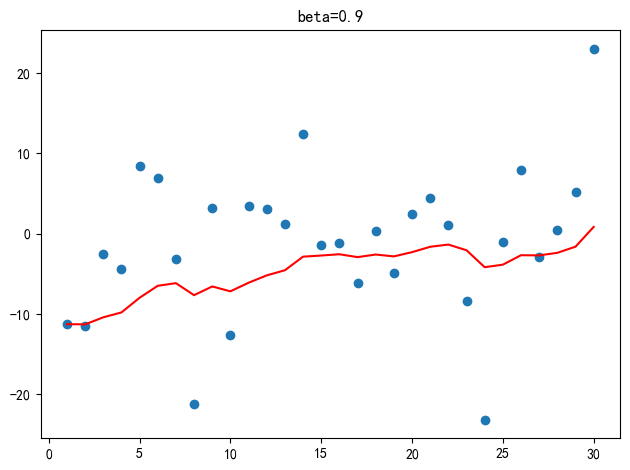

tensor([-11.2584, -11.5236,  -2.5058,  -4.3388,   8.4871,   6.9201,  -3.1601,
        -21.1522,   3.2227, -12.6333,   3.4998,   3.0813,   1.1984,  12.3766,
         -1.4347,  -1.1161,  -6.1358,   0.3159,  -4.9268,   2.4841,   4.3970,
          1.1241,  -8.4106, -23.1604,  -1.0231,   7.9244,  -2.8967,   0.5251,
          5.2286,  23.0221])


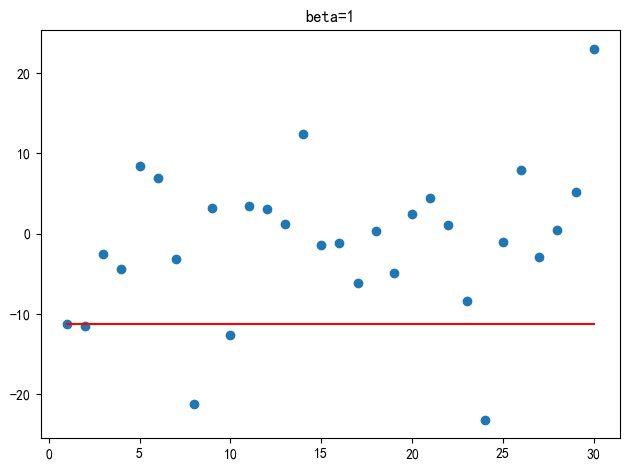

In [14]:
"""
案例:
    演示 移动加权平均，使用近30天的天气温度数据.

结论:
    对于移动加权平均, β值(调节权重系数)越大，移动加权平均值就越依赖历史数据；
    反之，β值(调节权重系数)越小，移动加权平均值就越依赖当天的数据。
    极端情况：β=1，移动加权平均值 = 第一天的数据；β=0，移动加权平均值 = 当天的数据。
"""

import torch
import matplotlib.pyplot as plt

ELEMENT_NUMBER = 30

# 1. 实际平均温度
def demo01():
    # 固定随机数种子
    torch.manual_seed(0)
    # 产生30天的随机温度
    temperature = torch.randn(size=[ELEMENT_NUMBER, ]) * 10
    print(temperature)
    # 绘制平均温度
    days = torch.arange(1, ELEMENT_NUMBER + 1, 1)
    plt.plot(days, temperature, color='r')
    plt.scatter(days, temperature)
    plt.tight_layout()
    plt.show()


# 2. 指数加权平均温度
def demo02(beta=0.9):
    # 固定随机数种子，确保每次运行得到相同的随机温度数据
    torch.manual_seed(0)
    # 产生30天的随机温度数据，通过乘以10放大温度范围
    temperature = torch.randn(size=[ELEMENT_NUMBER, ]) * 10
    print(temperature)

    # 存储指数加权平均后的温度值
    exp_weight_avg = []
    # 遍历每天的温度数据，idx从0开始计数
    for idx, temp in enumerate(temperature):
        # 第一天的指数加权平均值就是当天温度本身
        if idx == 0:
            exp_weight_avg.append(temp)
            continue
        # 从第二天开始，按照指数加权平均公式计算：
        # V_t = β * V_{t-1} + (1-β) * θ_t
        # 其中 V_t 是当前时刻的加权平均值，V_{t-1} 是上一时刻的加权平均值
        # θ_t 是当前时刻的实际温度值，β 是权重参数(0<=β<1)
        # idx-1 是因为要访问前一天的加权平均值
        new_temp = exp_weight_avg[idx - 1] * beta + (1 - beta) * temp
        exp_weight_avg.append(new_temp)

    # 创建天数序列用于绘图
    days = torch.arange(1, ELEMENT_NUMBER + 1, 1)
    # 设置图表标题，显示当前使用的beta值
    plt.title(f"beta={beta}")
    # 绘制指数加权平均温度曲线（红色）
    plt.plot(days, exp_weight_avg, color='r')
    # 绘制原始温度数据点
    plt.scatter(days, temperature)
    plt.tight_layout()
    # 显示图表
    plt.show()

if __name__ == '__main__':
    demo01()
    demo02(0)
    demo02(0.5)
    demo02(0.9)
    demo02(1)

###  动量算法Momentum

当梯度下降碰到 “峡谷” 、”平缓”、”鞍点” 区域时, 参数更新变慢。 Momentum 通过**指数加权平均法**，累计历史梯度值，进行参数更新，越近的梯度值对当前参数更新的影响越大。

**梯度计算公式**：

​				$$s_t=βs_{t−1}+(1−β)g_t$$

**参数更新公式**：

​				$$w_t=w_{t−1}−ηs_t$$

$s_t$是当前时刻的梯度的指数移动加权平均值

$s_{t-1}$是上一时刻的梯度的指数移动加权平均值

$g_t$是当前时刻的梯度值

β 是调节权重系数，通常取 0.9 或 0.99

η是学习率

$w_t$是当前时刻模型权重参数

In [15]:
print("梯度下降优化方法 —— 动量法Momentum")
# 1.初始化模型参数w
w = torch.tensor([1.0], requires_grad=True, dtype=torch.float32)
# 2.求损失值
loss = 0.5*(w**2)   # w
# 3.创建优化器，基于SGD, 加入动量 momentum(动量参数)，就是动量法
# 参数1：待优化的模型参数列表，参数2：学习率，参数3：动量参数
optimizer = optim.SGD([w], lr=0.01, momentum=0.9)   # momentum默认0，也就是无动量的随机梯度下降法
# 4.计算梯度，梯度清零 + 反向传播 + 更新参数
optimizer.zero_grad()   # 梯度清零
loss.mean().backward()  # 反向传播
optimizer.step()    # 更新参数
print(f"第一次梯度更新结果：\nw:{w}, w.grad: {w.grad}")

# 第二次计算损失值
loss = 0.5 * (w ** 2)  # w
optimizer.zero_grad()   # 梯度清零
loss.mean().backward()  # 反向传播
optimizer.step()    # 更新参数
print(f"第二次梯度更新结果：\nw:{w}, w.grad: {w.grad}")

梯度下降优化方法 —— 动量法Momentum
第一次梯度更新结果：
w:tensor([0.9900], requires_grad=True), w.grad: tensor([1.])
第二次梯度更新结果：
w:tensor([0.9711], requires_grad=True), w.grad: tensor([0.9900])


- **扩展 - Momentum 理论公式 vs SGD-Momentum 框架公式**

| 方面 | 理论公式 (Classical Momentum) | 框架公式 (PyTorch SGD-Momentum) |
|------|-------------------------------|---------------------------------|
| 动量计算 | $s_t = \beta s_{t-1} + (1-\beta) g_t$ | $s'_t = \beta s'_{t-1} + \eta g_t$ , 等价于$s_t = \beta s_{t-1} + g_t$ |
| 参数更新 | $w_t = w_{t-1} - \eta s_t$ | $w_t = w_{t-1} - s'_t$ |
| 梯度定义 | $g_t = \nabla L(w_{t-1})$ | $g_t = \nabla L(w_{t-1})$ |
| 动量定义 | $s_t$ 为累积梯度（速度） | $s'_t = \eta s_t$ 已包含学习率 |
| 区别 | 在参数更新时乘以学习率 | 学习率提前合并到动量计算中，取消了$(1-\beta)$缩放,更新直接减去动量 $s'_t$，就是Heavy Ball的工程实现 |

> Heavy Ball: 带惯性 + 阻尼的梯度下降，模拟 “重球在势能面滚动”，用动量保留运动惯性（冲过平坦区），用阻尼抑制震荡（避免过冲）


详细解释计算逻辑

In [16]:
w_init = 1.0
momentum = 0.9
lr = 0.01
# 计算梯度
g0 = w_init # 1.0
# 计算s0
s0 = 0 + lr*g0 # 0.01*1.0 = 0.01
# 计算w0
w0 = w_init - s0 # 1.0 - 0.01*1.0 = 0.99
print(f"第一次更新参数之后：w0: {w0}, g0: {g0}")
# 计算g1
g1 = w0 # 0.99
# 计算s1
s1 = momentum * s0 + lr * g1 # 0.9*0.01 + 0.01*0.99 = 0.009+0.0099 = 0.0189
# 计算w1
w1 = w0 - s1    # 0.99 - 0.0189 = 0.9711
print(f"w1: {w1}, g1: {g1}")

第一次更新参数之后：w0: 0.99, g0: 1.0
w1: 0.9711, g1: 0.99


In [16]:
w_init = 1.0
momentum = 0.95
lr = 0.01
# 计算梯度
g0 =2* w_init # 2.0
# 计算s0
s0 = 0 + lr*g0 # 0.01*2.0 = 0.02
# 计算w0
w0 = w_init - s0 # 1.0 - 0.02 = 0.98
print(f"第一次更新参数之后：w0: {w0}, g0: {g0}")
# 计算g1
g1 = 2*w0 # 1.96
# 计算s1
s1 = momentum * s0 + lr * g1 # 0.95*0.02 + 0.01*1.96 = 0.019 + 0.0196 = 0.0386
# 计算w1
w1 = w0 - s1    # 0.99 - 0.0189 = 0.9711
print(f"w1: {w1}, g1: {g1}")

第一次更新参数之后：w0: 0.98, g0: 2.0
w1: 0.9414, g1: 1.96


### AdaGrad

**AdaGrad 的学习率总体会逐渐减小**，AdaGrad 认为：在起初时，我们距离最优目标仍较远，可以使用较大的学习率，加快训练速度，随着迭代次数的增加，学习率逐渐下降。

其计算步骤如下：

1. 初始化学习率 η、初始化参数w、小常数 $σ = 1e-10$

2. 初始化梯度累计变量 s = 0
3. 从训练集中采样 m 个样本的小批量，计算梯度$g_t​$
4. **累积平方梯度**，⊙ 表示各个分量相乘, 公式为：

      $$s_t = s_{t-1} + g_t⊙g_t$$

5. 学习率 η 的计算公式如下：

$$η = \frac{η}{\sqrt{s_t}+σ}$$

6. 权重参数更新公式如下：

      ​			$$w_t    = w_{t-1} - \frac{η}{\sqrt{s_t}+σ} * g_t$$

7. 重复 3-7 步骤

**AdaGrad 缺点是可能会使得学习率过早、过量的降低，导致模型训练后期学习率太小，较难找到最优解。**

In [15]:
print("梯度下降优化方法 —— adagrad")
# 1.初始化模型参数w
w = torch.tensor([1.0], requires_grad=True, dtype=torch.float32)
# 2.求损失值
loss = 0.5*(w**2)   # w
# 3.创建优化器，基于SGD, 加入动量 momentum(动量参数)，就是动量法
# 参数1：待优化的模型参数列表，参数2：学习率，参数3：动量参数
# optimizer = optim.SGD([w], lr=0.01, momentum=0.9)   # momentum默认0，也就是无动量的随机梯度下降法
# 参数1：待优化的模型参数列表，参数2：学习率
optimizer = optim.Adagrad([w], lr=0.01)
# 4.计算梯度，梯度清零 + 反向传播 + 更新参数
optimizer.zero_grad()   # 梯度清零
loss.mean().backward()  # 反向传播
optimizer.step()    # 更新参数
print(f"第一次梯度更新结果：\nw:{w}, w.grad: {w.grad}")

# 第二次计算损失值
loss = 0.5 * (w ** 2)  # w
optimizer.zero_grad()   # 梯度清零
loss.mean().backward()  # 反向传播
optimizer.step()    # 更新参数
print(f"第二次梯度更新结果：\nw:{w}, w.grad: {w.grad}")

梯度下降优化方法 —— adagrad
第一次梯度更新结果：
w:tensor([0.9900], requires_grad=True), w.grad: tensor([1.])
第二次梯度更新结果：
w:tensor([0.9830], requires_grad=True), w.grad: tensor([0.9900])


###  RMSProp

**RMSProp 优化算法是对 AdaGrad 的优化**。主要不同是，使用**指数加权平均梯度**替换累计平方梯度。

其计算过程如下：

1. 初始化学习率 η、权重参数w、小常数 σ = 1e-10

2. 初始化梯度累计变量 s = 0

3. 从训练集中采样 m 个样本的小批量，计算梯度 $g_t$

4. 使用指数加权平均累计历史梯度，⊙ 表示各个分量相乘，公式如下：

      ​			$$s_t = βs_{t-1} + (1-β)g_t⊙g_t$$

5. 学习率 η 的计算公式如下：

$$η = \frac{η}{\sqrt{s_t}+σ}$$

6. 权重参数更新公式如下：

$$w_t    = w_{t-1} - \frac{η}{\sqrt{s_t}+σ} * g_t$$

7. 重复 3-7 步骤

RMSProp 与 AdaGrad 最大的区别是对梯度的累积方式不同，对于每个梯度分量仍然使用不同的学习率。

**RMSProp 通过引入衰减系数β，控制对历史梯度信息获取的多少**. 被证明在神经网络非凸条件下的优化更好，学习率衰减更加合理。

需要注意的是：AdaGrad 和 RMSProp 都是对于不同的参数分量使用不同的学习率，如果某个参数分量的梯度值较大，则对应的学习率就会较小，反之，则对应的学习率就会较大。

In [16]:
print("梯度下降优化方法 —— rmsprop")
# 1.初始化模型参数w
w = torch.tensor([1.0], requires_grad=True, dtype=torch.float32)
# 2.求损失值
loss = 0.5*(w**2)   # w
# 3.创建优化器，基于SGD, 加入动量 momentum(动量参数)，就是动量法
# 参数1：待优化的模型参数列表，参数2：学习率，参数3：动量参数
# optimizer = optim.SGD([w], lr=0.01, momentum=0.9)   # momentum默认0，也就是无动量的随机梯度下降法
# 参数1：待优化的模型参数列表，参数2：学习率
# optimizer = optim.Adagrad([w], lr=0.01)
# 参数1：待优化的模型参数列表，参数2：学习率，参数3：调和权重系数
optimizer = optim.RMSprop([w], lr=0.01, alpha=0.99)
# 4.计算梯度，梯度清零 + 反向传播 + 更新参数
optimizer.zero_grad()   # 梯度清零
loss.mean().backward()  # 反向传播
optimizer.step()    # 更新参数
print(f"第一次梯度更新结果：\nw:{w}, w.grad: {w.grad}")

# 第二次计算损失值
loss = 0.5 * (w ** 2)  # w
optimizer.zero_grad()   # 梯度清零
loss.mean().backward()  # 反向传播
optimizer.step()    # 更新参数
print(f"第二次梯度更新结果：\nw:{w}, w.grad: {w.grad}")

梯度下降优化方法 —— rmsprop
第一次梯度更新结果：
w:tensor([0.9000], requires_grad=True), w.grad: tensor([1.])
第二次梯度更新结果：
w:tensor([0.8329], requires_grad=True), w.grad: tensor([0.9000])


###  Adam（Adaptive Moment Estimation，自适应矩估计）

结合了 **Momentum** 和 **RMSProp** 的优点，通过计算梯度的一阶矩（均值）来调整梯度，二阶矩（平方）来调整学习率。
  - 修正梯度: 使⽤梯度的指数加权平均 
  - 修正学习率: 使⽤梯度平⽅的指数加权平均

**计算步骤：**

1. **梯度矩估计**：
  - 一阶矩：$m_t = β_1 m_{t-1} + (1-β_1) g_t$
  - 二阶矩：$s_t = β_2 s_{t-1} + (1-β_2) g_t^2$

2. **偏差校正**：
  - $\hat{m_t} = \frac{m_t}{1-β_1^t}$
  - $\hat{s_t} = \frac{s_t}{1-β_2^t}$

3. **参数更新**：
  $$w_t = w_{t-1} - \frac{η}{\sqrt{\hat{s_t}}+ϵ} \hat{m_t}$$

其中，$β_1$ 通常取 0.9，$β_2$ 通常取 0.999，$ϵ$ 为小常数（如 $10^{-8}$）防止除零。


In [17]:
print("梯度下降优化方法 —— adam")
# 1.初始化模型参数w
w = torch.tensor([1.0], requires_grad=True, dtype=torch.float32)
# 2.求损失值
loss = 0.5*(w**2)   # w
# 3.创建优化器，基于SGD, 加入动量 momentum(动量参数)，就是动量法
# 参数1：待优化的模型参数列表，参数2：学习率，参数3：动量参数
# optimizer = optim.SGD([w], lr=0.01, momentum=0.9)   # momentum默认0，也就是无动量的随机梯度下降法
# 参数1：待优化的模型参数列表，参数2：学习率
# optimizer = optim.Adagrad([w], lr=0.01)
# 参数1：待优化的模型参数列表，参数2：学习率，参数3：调和权重系数
# optimizer = optim.RMSprop([w], lr=0.01, alpha=0.99)
optimizer = optim.Adam([w], lr=0.01, betas=(0.9, 0.999), weight_decay=1e-3)
# 4.计算梯度，梯度清零 + 反向传播 + 更新参数
optimizer.zero_grad()   # 梯度清零
loss.mean().backward()  # 反向传播
optimizer.step()    # 更新参数
print(f"第一次梯度更新结果：\nw:{w}, w.grad: {w.grad}")

# 第二次计算损失值
loss = 0.5 * (w ** 2)  # w
optimizer.zero_grad()   # 梯度清零
loss.mean().backward()  # 反向传播
optimizer.step()    # 更新参数
print(f"第二次梯度更新结果：\nw:{w}, w.grad: {w.grad}")

梯度下降优化方法 —— adam
第一次梯度更新结果：
w:tensor([0.9900], requires_grad=True), w.grad: tensor([1.])
第二次梯度更新结果：
w:tensor([0.9800], requires_grad=True), w.grad: tensor([0.9900])


### AdamW 优化算法

AdamW（Adam with Weight Decay）是 Adam 优化器的一个变种，它在保持 Adam 优点的同时，修正了权重衰减（Weight Decay）的实现方式，在各种深度学习任务中展现出更好的泛化性能。

#### AdamW与Adam的核心区别

| 步骤 | Adam | AdamW |
|------|------|-------|
| **梯度计算** | $g_t = \nabla L(w_{t-1}) + \lambda w_{t-1}$ <br/> 权重衰减加入梯度 | $g_t = \nabla L(w_{t-1})$ <br/> 纯数据梯度 |
| **一阶矩估计** | $m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t$ | 同左 |
| **二阶矩估计** | $s_t = \beta_2 s_{t-1} + (1-\beta_2) g_t^2$ | 同左 |
| **偏差校正** | $\hat{m_t} = \frac{m_t}{1-\beta_1^t}, \quad \hat{s_t} = \frac{s_t}{1-\beta_2^t}$ | 同左 |
| **参数更新** | $w_t = w_{t-1} - \frac{\eta}{\sqrt{\hat{s_t}}+\epsilon} \hat{m_t}$ <br/> 权重衰减与自适应学习率耦合 | $w_t = (1-\eta\lambda) w_{t-1} - \frac{\eta}{\sqrt{\hat{s_t}}+\epsilon} \hat{m_t}$ <br/> 权重衰减添加到更新参数公式中 |

**核心优势**：AdamW 将权重衰减从梯度计算中解耦，实现真正的 L2 正则化，训练更稳定，是 Transformer 等现代模型的首选优化器。


In [18]:
print("梯度下降优化方法 —— adamw")
# 1.初始化模型参数w
w = torch.tensor([1.0], requires_grad=True, dtype=torch.float32)
# 2.求损失值
loss = 0.5*(w**2)   # w
# 3.创建优化器，基于SGD, 加入动量 momentum(动量参数)，就是动量法
# 参数1：待优化的模型参数列表，参数2：学习率，参数3：动量参数
# optimizer = optim.SGD([w], lr=0.01, momentum=0.9)   # momentum默认0，也就是无动量的随机梯度下降法
# 参数1：待优化的模型参数列表，参数2：学习率
# optimizer = optim.Adagrad([w], lr=0.01)
# 参数1：待优化的模型参数列表，参数2：学习率，参数3：调和权重系数
# optimizer = optim.RMSprop([w], lr=0.01, alpha=0.99)
optimizer = optim.AdamW([w], lr=0.01, betas=(0.9, 0.999), weight_decay=1e-3)
# 4.计算梯度，梯度清零 + 反向传播 + 更新参数
optimizer.zero_grad()   # 梯度清零
loss.mean().backward()  # 反向传播
optimizer.step()    # 更新参数
print(f"第一次梯度更新结果：\nw:{w}, w.grad: {w.grad}")

# 第二次计算损失值
loss = 0.5 * (w ** 2)  # w
optimizer.zero_grad()   # 梯度清零
loss.mean().backward()  # 反向传播
optimizer.step()    # 更新参数
print(f"第二次梯度更新结果：\nw:{w}, w.grad: {w.grad}")

梯度下降优化方法 —— adamw
第一次梯度更新结果：
w:tensor([0.9900], requires_grad=True), w.grad: tensor([1.])
第二次梯度更新结果：
w:tensor([0.9800], requires_grad=True), w.grad: tensor([0.9900])


| 优化算法 | 核心思想 | 核心变量（递推） | 参数更新 | 典型场景 | PyTorch 示例 |
|:--|:--|:--|:--|:--|:--|
| **SGD** | 使用当前梯度直接更新参数 | $g_t = \nabla L(w_{t-1})$ | $w_t = w_{t-1} - \eta g_t$ | 凸优化、简单模型 | `optim.SGD(params, lr=1e-3)` |
| **Momentum** | 累积历史梯度，加速收敛、减小震荡，可能跨过 鞍点 或 局部最小值 | $g_t = \nabla L(w_{t-1})$<br>$s_t = \beta s_{t-1} + (1-\beta) g_t$ | $w_t = w_{t-1} - \eta s_t$ | 深层网络 | `optim.SGD(params, lr=1e-2, momentum=0.9)` |
| **AdaGrad** | 自适应学习率，可能过早过快的降低学习率 | $g_t = \nabla L(w_{t-1})$<br>$s_t = s_{t-1} + g_t^2$ | $w_t = w_{t-1} - \dfrac{\eta}{\sqrt{s_t}+\epsilon} g_t$ | 稀疏特征（NLP） | `optim.Adagrad(params, lr=1e-2)` |
| **RMSProp** | 指数移动平均，缓解 AdaGrad 衰减过快，没有调整梯度，可能陷入 鞍点 或 局部最小值 | $g_t = \nabla L(w_{t-1})$<br>$s_t = \beta s_{t-1} + (1-\beta) g_t^2$ | $w_t = w_{t-1} - \dfrac{\eta}{\sqrt{s_t}+\epsilon} g_t$ | RNN / 非平稳目标 | `optim.RMSprop(params, lr=1e-3)` |
| **<span style="color:red">Adam</span>** | 同时调整 学习率 和 梯度：   一阶矩(调整梯度) + 二阶矩(调整学习率)自适应优化 | $$g_t=\nabla L(w_{t-1})+\lambda w_{t-1}$$ $$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t$$ $$s_t=\beta_2 s_{t-1}+(1-\beta_2)g_t^2$$ $$\hat m_t=\frac{m_t}{1-\beta_1^t}$$ $$\hat s_t=\frac{s_t}{1-\beta_2^t}$$ | $w_t=w_{t-1}-\dfrac{\eta}{\sqrt{\hat s_t}+\epsilon}\hat m_t$ | 通用深度学习 | `optim.Adam(params, lr=1e-3)` |
| **<span style="color:red">AdamW</span>** | Adam + 解耦权重衰减 | $g_t=\nabla L(w_{t-1})$<br>$m_t,s_t$ 同 Adam | $w_t=w_{t-1}-\dfrac{\eta}{\sqrt{\hat s_t}+\epsilon}\hat m_t-\eta\lambda w_{t-1}$ | Transformer / CV / NLP | `optim.AdamW(params, lr=1e-3, weight_decay=1e-3)` |


- 如何选择：AdamW（首选）/Adam -> SGD/Momentum

- **简单任务和较小的模型**：SGD 或 Momentum

- **复杂任务或有大量数据**： AdamW（首选）或 Adam，在大部分任务上都表现优秀

## 常见面试题

### 1. pytorch神经网络训练中为什么要在反向传播之前进行梯度清零？

- 因为PyTorch默认梯度会累积，如果不清零，多个反向传播梯度会相加，可能导致梯度爆炸或梯度消失，从而影响训练效果。
- 所以在每次反向传播前，需要调用 `optimizer.zero_grad()` 清零梯度。
---

### 2. 多分类交叉熵损失函数的公式是什么？
- 公式：$-\sum 真实类别 \log(预测概率)$，等价于 – log(正确类别的预测概率)。  
- 内部已包含 softmax 运算。
---

### 3. 二分类任务中，使用 多分类交叉熵损失 和 二分类交叉熵损失 时 应该注意哪些，有何区别？
  - 二分类任务，使用多分类交叉熵损失时，需要注意两个方面：
    - 1.网络输出层的输出维度为2，分别对应正类别和负类别；
    - 2.无需在网络输出层添加softmax，因为多分类交叉熵损失函数内部有softmax运算。
  - 使用二分类交叉熵损失时，需要注意两个方面：
    - 1.网络输出层的输出维度为1，输出对应正类别概率，负类别概率为1-正类别概率；
    - 2.需要在网络输出层添加sigmoid，因为二分类交叉熵损失函数内部没有sigmoid运算。
  
---

### 4.简述梯度下降法的原理
  - 梯度下降法的目标是找到损失函数的最小值，从而获取最优的模型参数。
  - 具体做法为，首先计算损失函数对模型参数的梯度，然后沿着梯度的反方向迭代更新模型参数，直到找到损失函数的最小值。
  - 更新参数的公式为：Wt = Wt-1 - 学习率 * 梯度

---

### 5. 梯度下降法的缺点有哪些？
  主要有三个：
  - 1.碰到小梯度的平缓区域，参数更新变慢；
  - 2.碰到0梯度的 “鞍点”，参数无法更新；
  - 3.可能陷入局部最小值，训练提前终止
  

---
### 6. 梯度下降法的优化方法有哪些？
  - 1.动量法Momentum
  - 2.自适应学习率AdaGrad
  - 3.RMSProp
  - 4.Adam/AdamW

---
### 7. 动量法是如何更新模型参数的？
  - 动量法Momentum 是一种优化方法，通过引入动量参数，来加速模型参数的更新。
  - 动量法Momentum 的更新公式为：
  St = β * St-1(上一次) + (1-β) * 梯度(当前)，
  Wt = Wt-1 - 学习率 * St, 
  St为梯度的指数加权平均值，β为权重系数，通常为0.9。
  
---
### 8. Adam是如何更新模型参数的？
  Adam 是结合 动量法Momentum 和 RMSProp 的自适应优化算法。
  - 1.对梯度做一阶矩和二阶矩的指数加权移动平均，得到mt 和 st
  - 2.再进行偏差校正得到mt_hat 和 st_hat
  - 3.然后按公式 Wt=Wt-1−学习率/(√st_hat + 小常数) * mt_hat，来更新模型参数，从而实现自适应学习率, 并加速收敛。

### 9. 神经网络的反向传播算法是如何求导的？
  - 反向传播通过**链式法则**在计算图上从输出向输入**反向计算梯度**。
  - 对任意参数，梯度是损失函数到该参数的**所有路径的梯度累加**，其中每条路径的梯度按链式法则相乘得到。
  - 本质上，损失函数对每个参数 w 的梯度是损失函数到参数 \( w \) 的所有路径的链式法则乘积之和：

  $$
  \frac{\partial L}{\partial w}
  =
  \sum_{\text{paths}}
  \prod
  \frac{\partial(\text{中间变量})}{\partial(\text{前一层})}
  $$

## 代码作业

- 1.搭建一个神经网络，有3个隐藏层和1个输出层，输入数据的输入特征维度为20，3个隐藏层的神经元数量分别为128，64，32，输出层的神经元数量为4。激活函数要求为：隐藏层使用relu激活函数，输出层使用softmax激活函数。并打印模型结构 和 模型参数。
- 2.使用代码演示 二分类任务中，分别使用 多分类交叉熵CrossEntropyLoss 和 二分类交叉熵BCELoss，比如原始输出的logits为：两个类别[[3,5], [4,5], [2,0]]，单个类别为[2,1,-2],分别计算对应的 多分类交叉熵损失值 和 二分类交叉熵损失值，并打印。
- 3.使用pytorch计算MSE损失值。已知 y_ture 为 [1, 2, 3, 4, 5, 6], y_pred 为 [2, 3, 4, 5, 6, 7]，计算MSE损失值，并打印。
- 4.使用梯度下降法，使用optim.SGD实现，循环迭代800次，求 loss = 0.5*w**2 + 10 的极小值点, 并打印loss最小值，以及loss是最小值时 w的值 和 梯度。
- 5.使用Adam优化器，使用optim.Adam实现，循环迭代800次，求 loss = 0.5*w**2 + 10 的极小值点, 并打印loss最小值，以及loss是最小值时 w的值 和 梯度。
- 6.使用AdamW优化器，使用optim.Adamw实现，循环迭代800次，求 loss = 0.5*w**2 + 10 的极小值点, 并打印loss最小值，以及loss是最小值时 w的值 和 梯度。

## 扩展- 多分类交叉熵nn.CrossEntropyLoss为什么自带 Softmax

核心原因：分开计算 Softmax + CrossEntropy 容易出现 数值溢出 / 损失异常 / 梯度无法计算。合并计算可以避免这些问题。

float32 数值范围：

| 数据类型 | 负数范围 | 正数范围 | 精度 |
|---|---|---|---|
| float32 | (-3.4 × 10³⁸, -1.18 × 10⁻³⁸) | (1.18 × 10⁻³⁸, 3.4 × 10³⁸) | 约7位有效数字 |


### 计算过程对比: 分开计算 vs 合并计算softmax + crossentropy

以三分类任务为例，假设真实类别为y = 1, 模型预测分数logits = [1000, 500, 100]，先减去最大值 m=1000：

| 步骤 | 分开计算：Softmax → CrossEntropy | 神经网络实现：CrossEntropy(logits) |
|---|---|---|
| 输入logits | [1000, 500, 100] | [1000, 500, 100] |
| 减去最大值得到新logits | [0, -500, -900] | [0, -500, -900] |
| 指数计算 | $[e^0, e^{-500}, e^{-900}] = [1, 0, 0]$（数值溢出，下溢截断为0） | 不单独计算 |
| Softmax概率$p_i$ | [1.0, 0.0, 0.0] | 不单独计算 |
| 计算损失 | $L=-∑y_i\log(p_i)$, $p_i$为 Softmax 概率 | $L= -∑y_i\log(e^{z_i}/\sum e^{z_j}) = -z_t+\log\sum e^{z_j}$, $z_t$为真实类别的 logit |
| 计算梯度(loss对所有类别的$logits$) | 链式求导，但log(0)导致无法计算梯度 | $softmax(logits) - y_i$, logits 为 logits 减去最大值后的结果, y_i 为 真实值 | 
| 真实类别为1时的损失值 | inf | $-500+\log(e^0+e^{-500}+e^{-900}) = -1000$ |
| 真实类别为1时的梯度 | 无法计算 | $softmax(logits) - y_i = [1, -1, 0]$ |


1. **损失值异常**：真实类别概率为0时，$-\log(0) = \inf$
2. **梯度消失**：概率为0的类别梯度为0，模型无法学习

**合并计算**直接基于logits计算损失 $L = -z_t + \log\sum_j e^{z_j - m}$，完全绕开了显式计算概率，避免了 数值溢出 / 损失异常 / 梯度无法计算。


## 扩展 - 实际项目中如何选择合适的优化器

**AdamW/Adam(90%) > pytorch-Momentum(10%) > 其他(1%)**

- **扩展 - Momentum 理论公式 vs SGD-Momentum 框架公式**

| 方面 | 理论公式 (Classical Momentum) | 框架公式 (PyTorch SGD-Momentum) |
|------|-------------------------------|---------------------------------|
| 动量计算 | $s_t = \beta s_{t-1} + (1-\beta) g_t$ | $s'_t = \beta s'_{t-1} + \eta g_t$ , 等价于$s_t = \beta s_{t-1} + g_t$ |
| 参数更新 | $w_t = w_{t-1} - \eta s_t$ | $w_t = w_{t-1} - s'_t$ |
| 梯度定义 | $g_t = \nabla L(w_{t-1})$ | $g_t = \nabla L(w_{t-1})$ |
| 动量定义 | $s_t$ 为累积梯度（速度） | $s'_t = \eta s_t$ 已包含学习率 |
| 区别 | 在参数更新时乘以学习率 | 学习率提前合并到动量计算中，取消了$(1-\beta)$缩放,更新直接减去动量 $s'_t$，就是Heavy Ball的工程实现 |

> Heavy Ball: 带惯性 + 阻尼的梯度下降，模拟 “重球在势能面滚动”，用动量保留运动惯性（冲过平坦区），用阻尼抑制震荡（避免过冲）